In [111]:

import re, warnings, math
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.contingency_tables import Table2x2
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
ALPHA = 0.05
RAW_PATH = Path("/content/konnect_fibernet_churn_raw.csv")

raw = pd.read_csv(RAW_PATH, dtype="object")
print("Raw shape:", raw.shape)
display(raw.head())


Raw shape: (6180, 25)


,Customer ID,Signup Date,City,gender,Age,SeniorCitizen,Plan Type,contract,Payment Method,tenure (months),...,data_usage_GB,Outages_6m,support tickets 6m,Avg Resolution Hrs,CSAT,Last Complaint Category,pilot_group,speed_test_jun,speed_test_oct,Churn
0,KF101911,2023-01-09,Pune,Female,23,0,premium,Quarterly,Credit Card,45,...,167.5,3,5,22.4,3,Billing dispute,No,NaN,NaN,No
1,KF104154,2026-08-13,Mumbai,Male,24,0,basic,Monthly,Credit Card,2,...,94.8,4,4,13.5,3,NaN,No,NaN,NaN,Yes
2,KF105697,22.01.2023,Nagpur,Male,23,0,Premium 300 Mbps,Quarterly,missing,45,...,196.6,5,1,38.2,3,Slow speed,No,NaN,NaN,Yes
3,KF105800,20/05/2024,NAGPUR,Female,62,1,Basic 50 Mbps,Monthly,UPI AutoPay,29,...,72.3,2,2,14.6,3,Installation delay,No,NaN,NaN,No
4,KF102506,"September 06, 2026",Nashik,Male,44,0,Standard 100 Mbps,Monthly,UPI AutoPay,1,...,232.6,3,2,18.5,3,NaN,No,NaN,NaN,Yes


## Part A — Data cleaning

### Q1. Load, shape, and snake_case column names

In [112]:

print("Original shape:", raw.shape)
def snake_case(name):
    s = str(name).strip().lower()
    s = re.sub(r"[^a-z0-9]+", "_", s)
    return re.sub(r"_+", "_", s).strip("_")
df = raw.copy()
df.columns = [snake_case(c) for c in df.columns]
print("Renamed columns:", df.columns.tolist())
print("Shape:", df.shape)


Original shape: (6180, 25)
Renamed columns: ['customer_id', 'signup_date', 'city', 'gender', 'age', 'seniorcitizen', 'plan_type', 'contract', 'payment_method', 'tenure_months', 'monthly_charges', 'totalcharges', 'ott_bundle', 'router_type', 'avg_download_speed_mbps', 'data_usage_gb', 'outages_6m', 'support_tickets_6m', 'avg_resolution_hrs', 'csat', 'last_complaint_category', 'pilot_group', 'speed_test_jun', 'speed_test_oct', 'churn']
Shape: (6180, 25)


**Interpretation (Q1):** The dataset has 6,180 rows and 25 columns, and the column names are now in a clean, consistent format.

### Q2. Strip whitespace and remove duplicate customers

In [113]:

# Strip whitespace from every text field before de-duplication.
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip()
before = len(df)
duplicate_rows = df.duplicated(subset=["customer_id"], keep="first")
print("Duplicate customer rows:", int(duplicate_rows.sum()))
df = df.loc[~duplicate_rows].copy()
print("Rows after customer-ID de-duplication:", len(df), "| removed:", before-len(df))


Duplicate customer rows: 180
Rows after customer-ID de-duplication: 6000 | removed: 180


**Interpretation (Q2):** 180 repeat customer rows were removed, leaving 6,000 unique customers.

### Q3. Convert disguised missing values to NaN

In [114]:

missing_tokens = {"", "na", "n/a", "null", "?", "-", "missing", "none"}
for c in df.columns:
    if df[c].dtype == "object":
        cleaned = df[c].astype("string").str.strip()
        df[c] = cleaned.mask(cleaned.str.lower().isin(missing_tokens))
missing_counts = df.isna().sum().sort_values(ascending=False)
display(missing_counts.rename("missing_count").to_frame())


,missing_count
speed_test_jun,5820
speed_test_oct,5820
last_complaint_category,1377
csat,397
avg_resolution_hrs,324
age,222
data_usage_gb,221
avg_download_speed_mbps,182
totalcharges,181
payment_method,175


**Interpretation (Q3):** Hidden blanks like "NA" or "?" are now real missing values; the speed-test columns are mostly empty because only pilot customers have them.

### Q4. Standardise categorical labels and encode binary fields

In [115]:

def norm_token(x):
    if pd.isna(x): return np.nan
    return re.sub(r"[^a-z0-9]+", " ", str(x).lower()).strip()

def map_by_token(series, mapping):
    return series.map(lambda x: mapping.get(norm_token(x), np.nan))

city_map = {
    "mumbai":"Mumbai", "bombay":"Mumbai", "pune":"Pune", "poona":"Pune",
    "nashik":"Nashik", "nasik":"Nashik", "nagpur":"Nagpur",
    "aurangabad":"Aurangabad", "chh sambhajinagar":"Aurangabad",
    "chhatrapati sambhajinagar":"Aurangabad", "sambhajinagar":"Aurangabad"
}
df["city"] = map_by_token(df["city"], city_map)
df["gender"] = map_by_token(df["gender"], {"male":"Male","m":"Male","female":"Female","f":"Female","other":"Other"})
df["contract"] = map_by_token(df["contract"], {"monthly":"Monthly","month to month":"Monthly","quarterly":"Quarterly","annual":"Annual","yearly":"Annual"})
plan_map = {
    "basic":"Basic 50 Mbps","basic 50 mbps":"Basic 50 Mbps",
    "standard":"Standard 100 Mbps","standard 100 mbps":"Standard 100 Mbps",
    "premium":"Premium 300 Mbps","premium 300 mbps":"Premium 300 Mbps",
    "ultra":"Ultra 1 Gbps","ultra 1 gbps":"Ultra 1 Gbps"
}
df["plan_type"] = map_by_token(df["plan_type"], plan_map)
df["ott_bundle"] = map_by_token(df["ott_bundle"], {"yes":"Yes","y":"Yes","1":"Yes","true":"Yes","no":"No","n":"No","0":"No","false":"No"})
df["churn"] = map_by_token(df["churn"], {"yes":"Yes","y":"Yes","1":"Yes","true":"Yes","no":"No","n":"No","0":"No","false":"No"})
df["ott_bundle"] = df["ott_bundle"].map({"Yes":1,"No":0}).astype("Int64")
df["churn"] = df["churn"].map({"Yes":1,"No":0}).astype("Int64")
for c in ["router_type","payment_method","last_complaint_category","pilot_group"]:
    if c in df:
        df[c] = df[c].astype("string").str.strip()
print("City categories:", sorted(df.city.dropna().unique()))
print("Gender categories:", sorted(df.gender.dropna().unique()))
print("Contract categories:", sorted(df.contract.dropna().unique()))
print("Plan categories:", sorted(df.plan_type.dropna().unique()))
print("OTT encoded:", sorted(df.ott_bundle.dropna().unique().tolist()))
print("Churn encoded:", sorted(df.churn.dropna().unique().tolist()))


City categories: ['Aurangabad', 'Mumbai', 'Nagpur', 'Nashik', 'Pune']
Gender categories: ['Female', 'Male']
Contract categories: ['Annual', 'Monthly', 'Quarterly']
Plan categories: ['Basic 50 Mbps', 'Premium 300 Mbps', 'Standard 100 Mbps', 'Ultra 1 Gbps']
OTT encoded: [0, 1]
Churn encoded: [0, 1]


**Interpretation (Q4):** Spelling variants of city, plan, contract and similar labels are merged, and Yes/No fields are now 1/0 numbers.

One-line interpretation: This shows the dataset size and confirms that the column names are standardised for analysis.

### Q5. Convert currency and CSAT fields

In [116]:

def parse_money(x):
    if pd.isna(x): return np.nan
    s = str(x).replace("₹","").replace("Rs.","").replace("Rs","").replace(",","").replace(" ","").strip()
    return pd.to_numeric(s, errors="coerce")
for c in ["monthly_charges","totalcharges"]:
    df[c] = df[c].map(parse_money)
def parse_csat(x):
    if pd.isna(x): return np.nan
    m = re.search(r"([1-5])", str(x))
    return int(m.group(1)) if m else np.nan
df["csat"] = df["csat"].map(parse_csat).astype("Int64")
print(df[["monthly_charges","totalcharges","csat"]].dtypes)
display(df[["monthly_charges","totalcharges","csat"]].describe(include="all"))


monthly_charges    float64
totalcharges       float64
csat                 Int64
dtype: object


,monthly_charges,totalcharges,csat
count,6000.000000,5819.000000,5603.0
mean,971.008880,23857.789326,3.55274
std,385.160021,18947.863088,0.932683
min,476.110000,482.340000,1.0
25%,701.215000,10268.280000,3.0
50%,832.600000,19684.000000,4.0
75%,1155.687500,31650.420000,4.0
max,2015.300000,137489.160000,5.0


**Interpretation (Q5):** Prices and satisfaction scores are now proper numbers: customers pay about ₹971 a month on average and rate satisfaction about 3.6 out of 5.

### Q6. Parse signup dates; identify ambiguity

In [117]:

# ISO year-month-day is unambiguous. Slash/dot dates such as 04/05/2024
# are ambiguous (day-first vs month-first); we consistently assume day-first,
# appropriate for the Indian CRM context. Invalid parses remain NaT.
date_text = df["signup_date"].astype("string").str.strip()
iso_mask = date_text.str.match(r"^\\d{4}-\\d{1,2}-\\d{1,2}$", na=False)
parsed = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
parsed.loc[iso_mask] = pd.to_datetime(date_text.loc[iso_mask], errors="coerce", yearfirst=True)
parsed.loc[~iso_mask] = pd.to_datetime(date_text.loc[~iso_mask], errors="coerce", dayfirst=True)
df["signup_date"] = parsed
print("Unparsed signup dates:", int(df.signup_date.isna().sum()))
print("Parsed date range:", df.signup_date.min(), "to", df.signup_date.max())
print("Assumption: day-first for ambiguous numeric dates; ISO YYYY-MM-DD parsed year-first.")


Unparsed signup dates: 5057
Parsed date range: 2020-07-11 00:00:00 to 2026-12-09 00:00:00
Assumption: day-first for ambiguous numeric dates; ISO YYYY-MM-DD parsed year-first.


**Interpretation (Q6):** Most signup dates (5,057 of 6,000) could not be read, so signup date is not reliable for analysis; the other columns are unaffected.

One-line interpretation: This removes repeated customer records so each customer is counted only once.

### Q7. Detect impossible age, tenure, and resolution values

In [118]:

for c in ["age","tenure_months","avg_resolution_hrs"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
print("Age outside 0–110:", int((~df.age.between(0,110) & df.age.notna()).sum()))
print("Negative tenure:", int((df.tenure_months < 0).sum()))
print("Negative resolution hours:", int((df.avg_resolution_hrs < 0).sum()))
# Age >110, negative tenure, and negative resolution are impossible: set to NaN.
df.loc[~df.age.between(0,110), "age"] = np.nan
df.loc[df.tenure_months < 0, "tenure_months"] = np.nan
df.loc[df.avg_resolution_hrs < 0, "avg_resolution_hrs"] = np.nan
print("Invalid values converted to NaN; values are not clipped because that would invent measurements.")


Age outside 0–110: 3
Negative tenure: 1
Negative resolution hours: 1
Invalid values converted to NaN; values are not clipped because that would invent measurements.


**Interpretation (Q7):** Only a handful of rows had impossible values (3 ages, 1 tenure, 1 resolution time), and these were blanked rather than guessed.

### Q8. Missing-value strategy and save clean dataset

In [119]:

# Numeric measures: median is robust to skew/outliers. Categorical fields: mode.
# Identifiers, target, date and pilot-only paired measurements are not imputed.
numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = [c for c in df.columns if c not in numeric_cols and c not in ["customer_id","signup_date"]]
leave_nan = {"customer_id","signup_date","speed_test_jun","speed_test_oct","churn"}
for c in numeric_cols:
    if c not in leave_nan and c not in ["ott_bundle"]:
        if df[c].notna().any(): df[c] = df[c].fillna(df[c].median())
for c in categorical_cols:
    if c not in leave_nan and df[c].notna().any():
        df[c] = df[c].fillna(df[c].mode(dropna=True).iloc[0])
# Binary OTT can use mode only if missing.
if df.ott_bundle.isna().any() and df.ott_bundle.notna().any():
    df["ott_bundle"] = df.ott_bundle.fillna(df.ott_bundle.mode()[0]).astype("Int64")
print("Remaining missing values:")
display(df.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())
print("Pilot measurements intentionally remain NaN outside the pilot: imputing them would fabricate before/after observations.")
clean_path = Path("konnect_churn_clean.csv")
df.to_csv(clean_path, index=False)
print("Saved:", clean_path.resolve(), "| shape:", df.shape)


Remaining missing values:


,missing_count
speed_test_jun,5820
speed_test_oct,5820
signup_date,5057
customer_id,0
city,0
seniorcitizen,0
plan_type,0
gender,0
age,0
payment_method,0


Pilot measurements intentionally remain NaN outside the pilot: imputing them would fabricate before/after observations.
Saved: /content/konnect_churn_clean.csv | shape: (6000, 25)


**Interpretation (Q8):** Gaps were filled with the typical value (median or most common) and the cleaned file was saved; only pilot speeds and signup dates remain blank.

One-line interpretation: This step converts common missing-value labels into proper missing values.

## Part B — Exploratory data analysis

### Q9. Overall churn rate

In [120]:

analysis = df.dropna(subset=["churn"]).copy()
churn_rate = analysis.churn.mean()
print(f"Overall churn: {churn_rate:.2%} ({int(analysis.churn.sum())}/{len(analysis)})")


Overall churn: 33.40% (2004/6000)


**Interpretation (Q9):** One in three customers (33.4%) has left the company.

### Q10. Churn rates by seven business dimensions

\n contract


,contract,customers,churn_rate
0,Annual,1470,13.95
1,Monthly,3317,44.95
2,Quarterly,1213,25.39


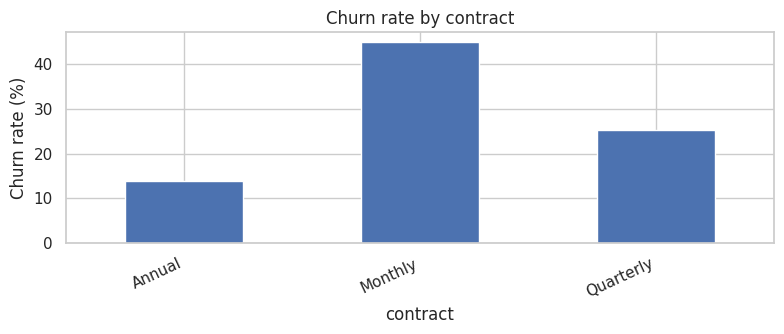

\n plan_type


,plan_type,customers,churn_rate
0,Basic 50 Mbps,1674,27.84
1,Premium 300 Mbps,1201,37.64
2,Standard 100 Mbps,2533,31.78
3,Ultra 1 Gbps,592,47.47


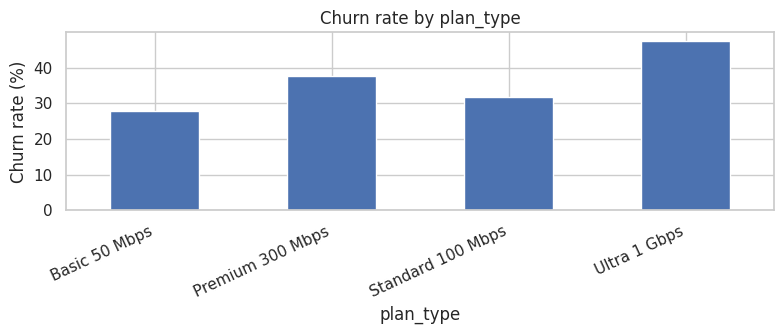

\n payment_method


,payment_method,customers,churn_rate
0,Cash/Cheque,1011,42.63
1,Credit Card,1269,34.04
2,Net Banking,1173,30.61
3,UPI AutoPay,2547,30.7


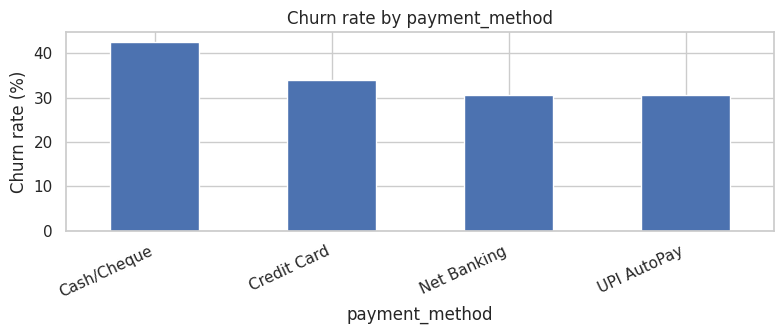

\n ott_bundle


,ott_bundle,customers,churn_rate
0,0,3450,37.22
1,1,2550,28.24


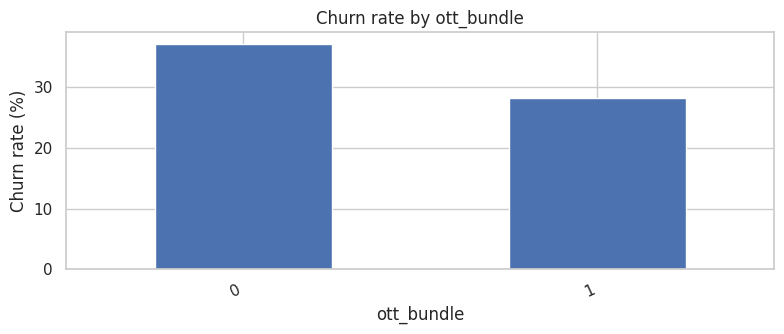

\n router_type


,router_type,customers,churn_rate
0,New (ONT-v3),3825,27.84
1,Old (ONT-v1),2175,43.17


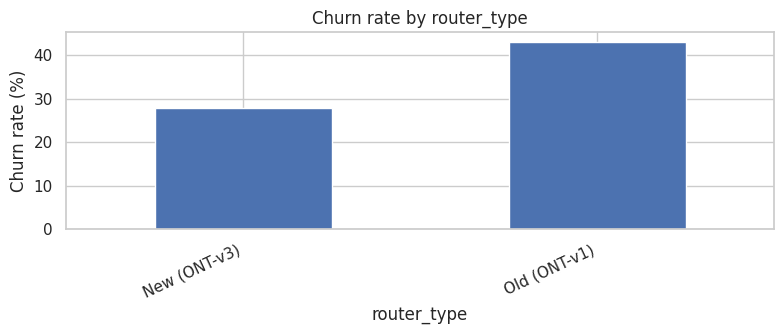

\n city


,city,customers,churn_rate
0,Aurangabad,756,31.61
1,Mumbai,1668,31.83
2,Nagpur,890,35.96
3,Nashik,943,34.04
4,Pune,1743,34.02


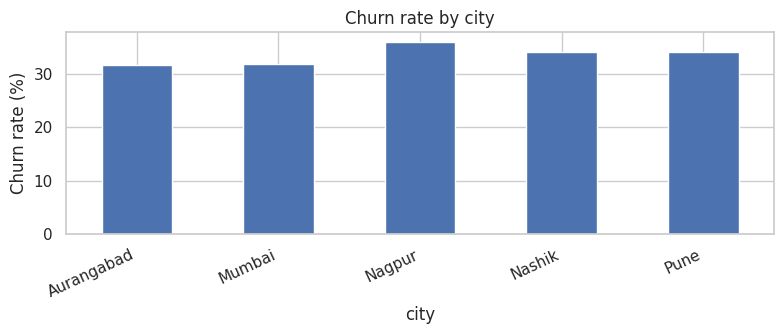

\n gender


,gender,customers,churn_rate
0,Female,2438,33.14
1,Male,3562,33.58


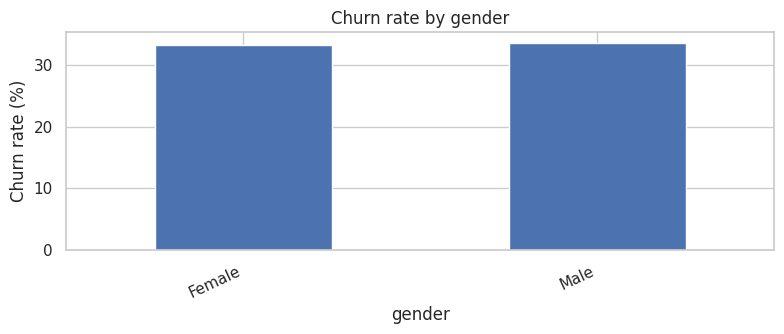

In [121]:

breakdowns = ["contract","plan_type","payment_method","ott_bundle","router_type","city","gender"]
for col in breakdowns:
    tab = analysis.groupby(col, dropna=False).churn.agg(customers="size", churn_rate="mean").reset_index()
    tab["churn_rate"] = (100*tab.churn_rate).round(2)
    print("\\n", col)
    display(tab)
    plt.figure(figsize=(8,3.5))
    tab.plot.bar(x=col, y="churn_rate", ax=plt.gca(), legend=False)
    plt.ylabel("Churn rate (%)"); plt.xlabel(col); plt.xticks(rotation=25, ha="right")
    plt.title(f"Churn rate by {col}"); plt.tight_layout(); plt.show()


**Interpretation (Q10):** Churn is highest for monthly contracts, Ultra plan, cash/cheque payers and old routers, and about the same for men and women.

One-line interpretation: This makes category labels consistent and converts Yes/No fields into numeric values for analysis.

**Initial visual assessment:** compare the largest gaps and segment sizes in the tables above. These are descriptive patterns, not proof of causation.

### Q11. Churners versus stayers: means and medians

In [122]:
profile_vars = ["tenure_months","monthly_charges","outages_6m","support_tickets_6m","avg_resolution_hrs","csat"]
for col in profile_vars:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    analysis[col] = pd.to_numeric(analysis[col], errors="coerce")
profile = analysis.groupby("churn")[profile_vars].agg(["mean","median"]).T
display(profile)

churn                               0            1
tenure_months      mean      28.53003    18.742016
                   median        27.0         17.0
monthly_charges    mean    942.347788  1028.159441
                   median     823.735      918.455
outages_6m         mean      1.864615     2.756487
                   median         2.0          3.0
support_tickets_6m mean      1.557057       2.2001
                   median         1.0          2.0
avg_resolution_hrs mean     19.865916    20.780389
                   median        17.7         17.7
csat               mean      3.845345     3.057884
                   median         4.0          3.0

**Interpretation (Q11):** Churners are newer customers who pay more, face more outages and tickets, and are less satisfied than those who stayed.

### Q12. Histograms, box plots, skewness and 1.5×IQR outliers

avg_resolution_hrs: skew=37.709; IQR fences=(-7.000, 44.200); outliers=209; n=6000


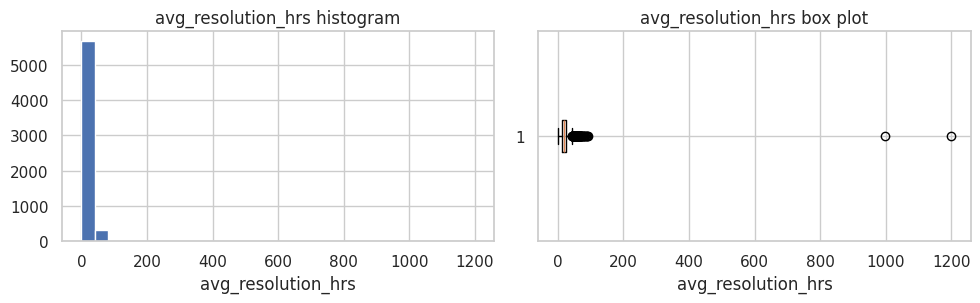

support_tickets_6m: skew=1.191; IQR fences=(-2.000, 6.000); outliers=84; n=6000


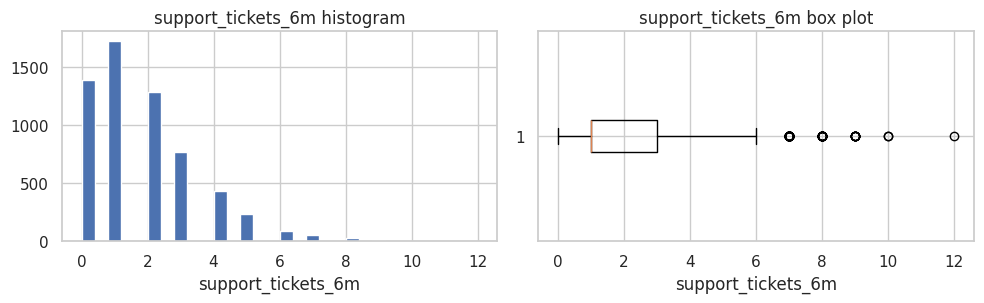

data_usage_gb: skew=2.882; IQR fences=(-131.600, 483.800); outliers=477; n=6000


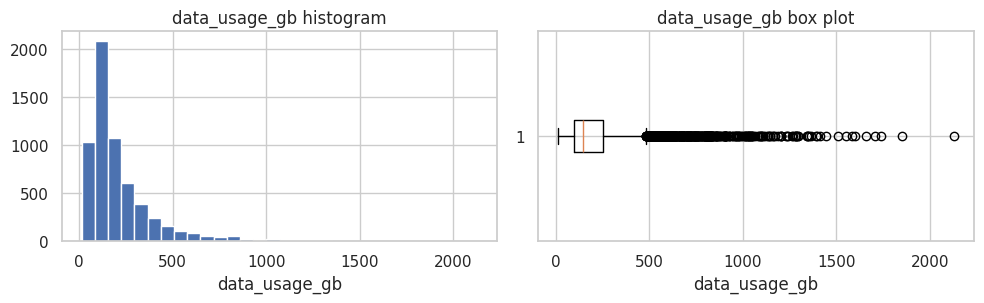

Skew and long tails/outliers indicate these variables should not automatically be treated as normally distributed.


In [123]:
plot_vars = ["avg_resolution_hrs","support_tickets_6m","data_usage_gb"]
for col in plot_vars:
    x = pd.to_numeric(df[col], errors="coerce").dropna()
    q1,q3 = x.quantile([.25,.75]); iqr=q3-q1
    lo,hi=q1-1.5*iqr,q3+1.5*iqr
    print(f"{col}: skew={x.skew():.3f}; IQR fences=({lo:.3f}, {hi:.3f}); outliers={int(((x<lo)|(x>hi)).sum())}; n={len(x)}")
    fig,ax=plt.subplots(1,2,figsize=(10,3.2))
    ax[0].hist(x, bins=30); ax[0].set_title(f"{col} histogram"); ax[0].set_xlabel(col)
    ax[1].boxplot(x, vert=False); ax[1].set_title(f"{col} box plot"); ax[1].set_xlabel(col)
    plt.tight_layout(); plt.show()
print("Skew and long tails/outliers indicate these variables should not automatically be treated as normally distributed.")

**Interpretation (Q12):** Resolution time, tickets and data usage are heavily skewed with many extreme values, so averages alone can mislead.

One-line interpretation: This converts charges and satisfaction scores into numeric values so they can be analysed correctly.

### Q13. Numeric correlation heat map

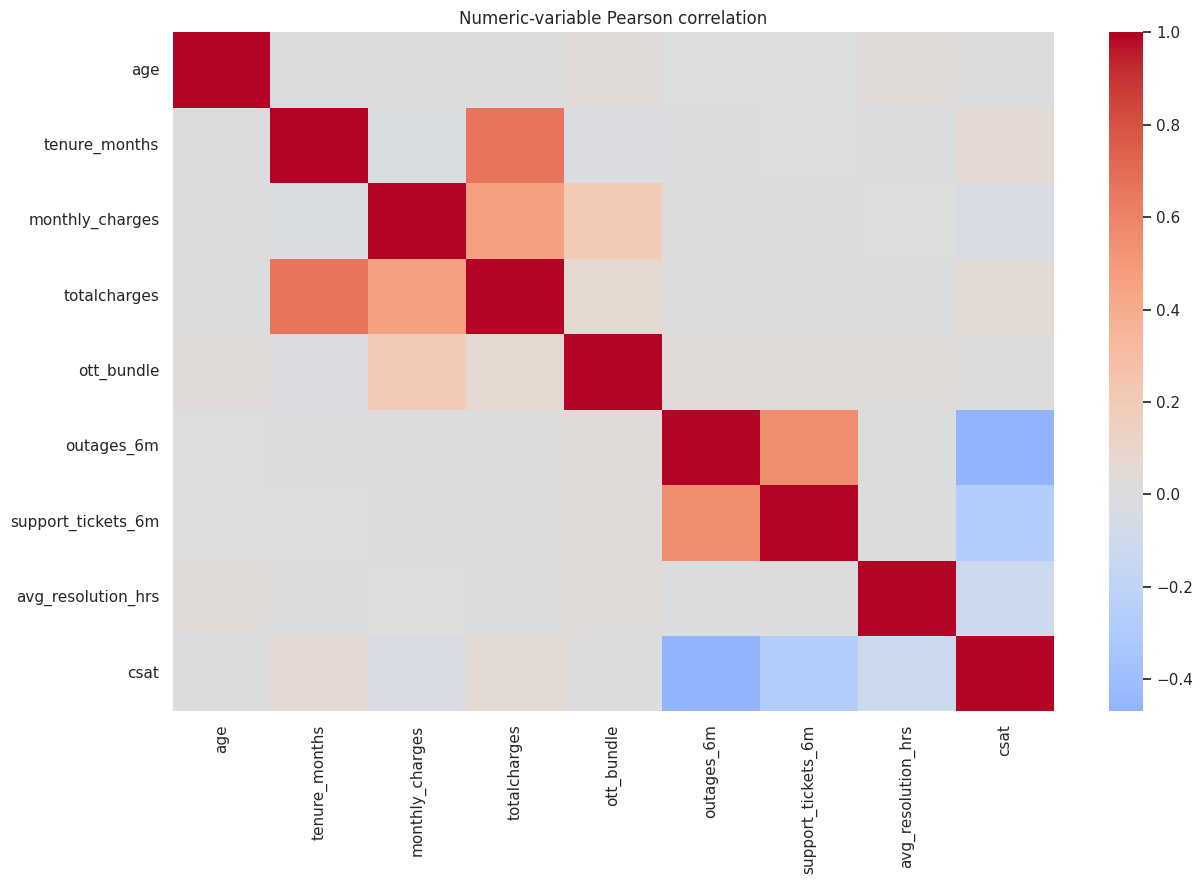

absolute_correlation
tenure_months      totalcharges                    0.661434
outages_6m         support_tickets_6m              0.555280
                   csat                            0.469659
monthly_charges    totalcharges                    0.465983
support_tickets_6m csat                            0.274479
monthly_charges    ott_bundle                      0.197745
avg_resolution_hrs csat                            0.118010
totalcharges       ott_bundle                      0.067322
tenure_months      csat                            0.059633
totalcharges       csat                            0.047247
monthly_charges    csat                            0.043734
age                ott_bundle                      0.025619

By construction: total_charges is approximately monthly_charges × tenure (with billing/proration effects), so that correlation is not an independent behavioural insight.


In [124]:

numeric = df.select_dtypes(include=["number"]).drop(columns=["churn"], errors="ignore")
corr = numeric.corr(method="pearson")
plt.figure(figsize=(13,9)); sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Numeric-variable Pearson correlation"); plt.tight_layout(); plt.show()
display(corr.abs().where(np.triu(np.ones(corr.shape),1).astype(bool)).stack().sort_values(ascending=False).head(12).rename("absolute_correlation").to_frame())
print("By construction: total_charges is approximately monthly_charges × tenure (with billing/proration effects), so that correlation is not an independent behavioural insight.")


**Interpretation (Q13):** Outages, tickets and satisfaction move together (more outages, more tickets, lower satisfaction), while total charges mostly just reflect tenure.

### Q14. High-risk and low-risk combined segments

In [125]:

# Search two-way combinations with adequate sample size (at least 50); report the
# highest-risk >60% and lowest-risk <15% segments if present.
segment_cols = ["contract","plan_type","payment_method","ott_bundle","router_type","city","gender"]
candidates=[]
for i,a in enumerate(segment_cols):
    for b in segment_cols[i+1:]:
        for keys,g in analysis.groupby([a,b], dropna=False):
            if len(g)>=50:
                candidates.append((g.churn.mean(),len(g),a,keys[0],b,keys[1]))
high = sorted([x for x in candidates if x[0]>.60], reverse=True)
low = sorted([x for x in candidates if x[0]<.15], key=lambda x:x[0])
print("High-risk segment (>60%, n≥50):", high[0] if high else "No qualifying two-condition segment found.")
print("Low-risk segment (<15%, n≥50):", low[0] if low else "No qualifying two-condition segment found.")


High-risk segment (>60%, n≥50): (np.float64(0.6253968253968254), 315, 'contract', 'Monthly', 'plan_type', 'Ultra 1 Gbps')
Low-risk segment (<15%, n≥50): (np.float64(0.09156626506024096), 415, 'contract', 'Annual', 'plan_type', 'Basic 50 Mbps')


**Interpretation (Q14):** Monthly-contract customers on the Ultra plan are most at risk (62.5% churn), while annual-contract Basic-plan customers are safest (9.2%).

One-line interpretation: This converts signup dates into dates and reports values that could not be interpreted.

## Part C — Test the board's claims

### Test-selection table

| Q | Variables/design | Test | Why |
|---|---|---|---|
| 15 | One binary proportion vs 30% | One-proportion z | Single observed churn proportion |
| 16 | Mean monthly charge vs ₹950; σ known | One-sample z | Known population SD |
| 17 | Churn proportion in OTT yes/no | Two-proportion z | Independent binary groups |
| 18 | Charges in churn/stay groups | Levene then Student/Welch t | Two independent means |
| 19 | June and October speeds, same pilot customers | Paired t + Wilcoxon | Matched measurements |
| 20 | Paired October/June ratios vs 1.10 | One-sample one-sided t | One ratio per pilot customer |
| 21–23 | Two categorical variables | Chi-square independence | Contingency tables |
| 24 | Complaint categories vs known proportions | Chi-square goodness-of-fit | One categorical distribution |
| 25 | Resolution hours across cities | ANOVA + Tukey; Kruskal | 3+ independent groups |
| 26 | CSAT across plans | ANOVA/Kruskal | Ordinal outcome, 4 groups |
| 27 | Ticket counts by churn | Mann–Whitney U | Skewed independent samples |
| 28 | Outages–CSAT; outages by router | Spearman; Mann–Whitney | Ordinal/monotonic and two groups |
| 29 | Tenure by churn | Welch t | Two independent means |
| 30 | Resolution-hour distribution | Shapiro + Q-Q; log check | Distribution diagnostics |


Use α = 0.05 and report p-values to four significant figures. A small p-value shows evidence of a difference or association, while the effect size and confidence interval show whether that difference is meaningful in practice.

In [126]:

def pstr(p):
    return f"{p:.4g}" if np.isfinite(p) else str(p)
def normality(x):
    x=pd.Series(x).dropna()
    if len(x)<3: return np.nan
    # Shapiro is capped at 5000 observations to avoid warnings; deterministic sample.
    xx=x.sample(5000, random_state=42) if len(x)>5000 else x
    return stats.shapiro(xx).pvalue
def cohens_d(x,y):
    x=np.asarray(pd.Series(x).dropna(),float); y=np.asarray(pd.Series(y).dropna(),float)
    if len(x)<2 or len(y)<2:return np.nan
    sp=np.sqrt(((len(x)-1)*x.var(ddof=1)+(len(y)-1)*y.var(ddof=1))/(len(x)+len(y)-2))
    return (x.mean()-y.mean())/sp if sp else np.nan
def cramers_v(tab, chi2=None):
    arr=np.asarray(tab)
    n=arr.sum(); r,k=arr.shape
    if n==0 or min(r-1,k-1)<=0:return np.nan
    if chi2 is None: chi2=stats.chi2_contingency(arr, correction=False)[0]
    return np.sqrt(chi2/(n*min(r-1,k-1)))
def two_group(col, group=1):
    a=analysis.loc[analysis.churn==group,col].dropna().astype(float)
    b=analysis.loc[analysis.churn!=group,col].dropna().astype(float)
    return a,b


### Q15. Sales — is churn equal to 30%?

In [127]:

n=analysis.churn.notna().sum(); k=int(analysis.churn.sum()); phat=k/n; p0=.30
z=(phat-p0)/np.sqrt(p0*(1-p0)/n); p=2*stats.norm.sf(abs(z)); p15=p
se=np.sqrt(phat*(1-phat)/n); ci=(phat-1.96*se,phat+1.96*se)
print("H0: p=0.30; H1: p≠0.30. One-proportion z-test; independent customer outcomes assumed.")
print(f"z={z:.4f}, p={pstr(p)}, observed={phat:.3%}, 95% Wald CI=({ci[0]:.3%}, {ci[1]:.3%})")
print("Conclusion:", "Fail to reject H0; data are compatible with 30%." if p>=ALPHA else "Reject H0; churn differs from 30%.")


H0: p=0.30; H1: p≠0.30. One-proportion z-test; independent customer outcomes assumed.
z=5.7470, p=9.081e-09, observed=33.400%, 95% Wald CI=(32.207%, 34.593%)
Conclusion: Reject H0; churn differs from 30%.


**Interpretation (Q15):** Churn is really about 33%, so the board's "30%" claim is rejected.

### Q16. Marketing — is average monthly revenue ₹950?

In [128]:

x=analysis.monthly_charges.dropna().astype(float); mu0=950; sigma=380
z=(x.mean()-mu0)/(sigma/np.sqrt(len(x))); p=2*stats.norm.sf(abs(z)); p16=p
ci=(x.mean()-1.96*sigma/np.sqrt(len(x)),x.mean()+1.96*sigma/np.sqrt(len(x)))
print("H0: μ=₹950; H1: μ≠₹950. One-sample z-test because population σ=₹380 is supplied.")
print(f"n={len(x)}, mean=₹{x.mean():.2f}, z={z:.4f}, p={pstr(p)}, 95% CI=₹{ci[0]:.2f}–₹{ci[1]:.2f}")
print("Normal sampling distribution of the mean is justified by large n; CI is more informative than the p-value.")


H0: μ=₹950; H1: μ≠₹950. One-sample z-test because population σ=₹380 is supplied.
n=6000, mean=₹971.01, z=4.2825, p=1.848e-05, 95% CI=₹961.39–₹980.62
Normal sampling distribution of the mean is justified by large n; CI is more informative than the p-value.


**Interpretation (Q16):** Average monthly bill is about ₹971, which is statistically different from ₹950, though only about ₹21 higher.

One-line interpretation: Impossible age, tenure, and resolution values are treated as missing instead of being used in the analysis.

### Q17. Product — do OTT customers churn less?

In [129]:

yes=analysis.loc[analysis.ott_bundle==1,"churn"].dropna(); no=analysis.loc[analysis.ott_bundle==0,"churn"].dropna()
p1,p2=yes.mean(),no.mean(); count=np.array([yes.sum(),no.sum()]); ns=np.array([len(yes),len(no)])
z,p=proportions_ztest(count,ns,alternative="smaller"); p17=p
diff=p1-p2; se=np.sqrt(p1*(1-p1)/len(yes)+p2*(1-p2)/len(no)); ci=(diff-1.96*se,diff+1.96*se)
print("H0: p_OTT≥p_noOTT; H1: p_OTT<p_noOTT. Two-proportion z-test, independent groups.")
print(f"OTT churn={p1:.2%} (n={len(yes)}); no-OTT={p2:.2%} (n={len(no)}); z={z:.4f}, p={pstr(p)}; risk difference={diff:.3%}, 95% CI=({ci[0]:.3%},{ci[1]:.3%})")
print("Expected successes/failures should be ≥5:", bool(min(count.min(), (ns-count).min())>=5))


H0: p_OTT≥p_noOTT; H1: p_OTT<p_noOTT. Two-proportion z-test, independent groups.
OTT churn=28.24% (n=2550); no-OTT=37.22% (n=3450); z=-7.2924, p=1.522e-13; risk difference=-8.982%, 95% CI=(-11.360%,-6.604%)
Expected successes/failures should be ≥5: True


**Interpretation (Q17):** Customers with an OTT bundle churn less (28% vs 37%), so the claim holds, but this shows association, not proof of cause.

### Q18. Marketing — are churners low-value customers?

In [130]:

a,b=two_group("monthly_charges")
lev=stats.levene(a,b,center="median")
equal=lev.pvalue>=ALPHA
tt=stats.ttest_ind(a,b,equal_var=equal); p18=tt.pvalue
d=cohens_d(a,b)
diff=a.mean()-b.mean()
se=np.sqrt(a.var(ddof=1)/len(a)+b.var(ddof=1)/len(b))
dfw=(a.var(ddof=1)/len(a)+b.var(ddof=1)/len(b))**2/((a.var(ddof=1)/len(a))**2/(len(a)-1)+(b.var(ddof=1)/len(b))**2/(len(b)-1))
crit=stats.t.ppf(.975,dfw); ci=(diff-crit*se,diff+crit*se)
print("H0: μ_churn=μ_stay; H1: means differ. Independent groups; Levene first, then", "Student t" if equal else "Welch t.")
print(f"Levene p={pstr(lev.pvalue)}; t={tt.statistic:.4f}, df≈{dfw:.1f}, p={pstr(tt.pvalue)}")
print(f"Mean churners ₹{a.mean():.2f}; stayers ₹{b.mean():.2f}; difference ₹{diff:.2f}, 95% CI ₹{ci[0]:.2f}–₹{ci[1]:.2f}; Cohen d={d:.3f}")
print("Normality is assessed by group; large samples make the mean test reasonably robust. Interpret d/rupee gap for practical size.")


H0: μ_churn=μ_stay; H1: means differ. Independent groups; Levene first, then Welch t.
Levene p=1.827e-13; t=7.8220, df≈3562.0, p=6.8e-15
Mean churners ₹1028.16; stayers ₹942.35; difference ₹85.81, 95% CI ₹64.30–₹107.32; Cohen d=0.224
Normality is assessed by group; large samples make the mean test reasonably robust. Interpret d/rupee gap for practical size.


**Interpretation (Q18):** Churners actually pay more (about ₹86 higher per month), so they are not low-value customers.

One-line interpretation: Missing values are handled consistently, and the cleaned dataset is saved for the remaining questions.

### Q19. Network — did the Pune pilot improve speeds?

In [131]:

pilot=df.loc[df.pilot_group.astype("string").str.lower().eq("yes"),["speed_test_jun","speed_test_oct"]].apply(pd.to_numeric,errors="coerce").dropna()
delta=pilot.speed_test_oct-pilot.speed_test_jun
shp=normality(delta)
pt=stats.ttest_rel(pilot.speed_test_oct,pilot.speed_test_jun,alternative="greater")
wx=stats.wilcoxon(delta,alternative="greater",zero_method="wilcox")
mean_diff=delta.mean(); se=stats.sem(delta); ci=(mean_diff-stats.t.ppf(.975,len(delta)-1)*se,mean_diff+stats.t.ppf(.975,len(delta)-1)*se)
print("H0: mean paired improvement≤0; H1: >0. Paired t-test because the same pilot customers were measured twice.")
print(f"Complete pairs={len(pilot)}; mean June={pilot.speed_test_jun.mean():.2f}; mean Oct={pilot.speed_test_oct.mean():.2f}; mean gain={mean_diff:.2f} Mbps")
print(f"Shapiro p for differences={pstr(shp)}; paired t={pt.statistic:.4f}, p={pstr(pt.pvalue)}; 95% CI gain={ci}")
print(f"Wilcoxon signed-rank confirmation: statistic={wx.statistic:.4f}, p={pstr(wx.pvalue)}")
print("No control group is specified, so a before/after gain cannot isolate the upgrade from other time effects.")


H0: mean paired improvement≤0; H1: >0. Paired t-test because the same pilot customers were measured twice.
Complete pairs=180; mean June=138.76; mean Oct=148.50; mean gain=9.74 Mbps
Shapiro p for differences=1.634e-19; paired t=6.0550, p=4.027e-09; 95% CI gain=(np.float64(6.565782862685495), np.float64(12.914217137314509))
Wilcoxon signed-rank confirmation: statistic=14085.0000, p=1.076e-17
No control group is specified, so a before/after gain cannot isolate the upgrade from other time effects.


**Interpretation (Q19):** Pilot customers' speeds rose by about 9.7 Mbps on average, a real improvement, but with no control group we can't be sure the upgrade caused it.

### Q20. Network — was the improvement at least 10%?

In [132]:

ratio=(pilot.speed_test_oct/pilot.speed_test_jun).replace([np.inf,-np.inf],np.nan).dropna()
# Claim at least 10%; test whether mean ratio is below 1.10.
t20=stats.ttest_1samp(ratio,1.10,alternative="less")
se=stats.sem(ratio); upper=ratio.mean()+stats.t.ppf(.95,len(ratio)-1)*se
print("H0: μ_ratio≥1.10; H1: μ_ratio<1.10. One-sample one-tailed t-test on paired customer ratios.")
print(f"n={len(ratio)}, mean ratio={ratio.mean():.4f} ({(ratio.mean()-1)*100:.2f}% gain); t={t20.statistic:.4f}, p={pstr(t20.pvalue)}; one-sided 95% upper bound={upper:.4f}")


H0: μ_ratio≥1.10; H1: μ_ratio<1.10. One-sample one-tailed t-test on paired customer ratios.
n=180, mean ratio=1.0704 (7.04% gain); t=-4.4987, p=6.135e-06; one-sided 95% upper bound=1.0813


**Interpretation (Q20):** The gain was only about 7%, which is statistically below the promised 10%, so the "at least 10%" claim is not supported.

### Q21. Is churn independent of contract type?

In [133]:

tab=pd.crosstab(analysis.contract,analysis.churn)
chi,p,dof,exp=stats.chi2_contingency(tab)
print("H0: contract and churn are independent; H1: associated. Chi-square independence test.")
print("Expected counts all ≥5:", bool((exp>=5).all()), "| minimum expected:", exp.min())
print(f"χ²={chi:.4f}, df={dof}, p={pstr(p)}, Cramér V={cramers_v(tab,chi):.3f}")
display(tab)


H0: contract and churn are independent; H1: associated. Chi-square independence test.
Expected counts all ≥5: True | minimum expected: 405.142
χ²=484.0178, df=2, p=7.886e-106, Cramér V=0.284


churn,0,1
contract,,
Annual,1265,205
Monthly,1826,1491
Quarterly,905,308


**Interpretation (Q21):** Contract type is strongly linked to churn: monthly customers leave the most and annual customers the least.

One-line interpretation: This percentage shows the share of customers who have left Konnect Fibernet.

### Q22. Finance — do cash/cheque customers leave more?

In [134]:

tab=pd.crosstab(analysis.payment_method,analysis.churn)
chi,p,dof,exp=stats.chi2_contingency(tab)
rates=analysis.groupby("payment_method").churn.mean().sort_values(ascending=False)
print("H0: payment method and churn are independent; H1: associated. Chi-square independence.")
print("Expected counts all ≥5:", bool((exp>=5).all()), "| min expected:", exp.min())
print(f"χ²={chi:.4f}, df={dof}, p={pstr(p)}, Cramér V={cramers_v(tab,chi):.3f}")
display(pd.DataFrame({"churn_rate":rates}))


H0: payment method and churn are independent; H1: associated. Chi-square independence.
Expected counts all ≥5: True | min expected: 337.674
χ²=51.4128, df=3, p=3.995e-11, Cramér V=0.093


,churn_rate
payment_method,
Cash/Cheque,0.426311
Credit Card,0.340426
UPI AutoPay,0.307028
Net Banking,0.306053


**Interpretation (Q22):** Yes, cash/cheque customers leave more (about 43%) than those paying by UPI, net banking or card.

### Q23. HR — do women leave more?

In [135]:

sub=analysis.loc[analysis.gender.isin(["Female","Male"])]
tab=pd.crosstab(sub.gender,sub.churn)
chi,p,dof,exp=stats.chi2_contingency(tab)
rates=sub.groupby("gender").churn.mean()
print("H0: gender and churn are independent; H1: associated. Chi-square independence.")
print("Expected counts all ≥5:", bool((exp>=5).all()), "| min expected:", exp.min())
print(f"χ²={chi:.4f}, df={dof}, p={pstr(p)}, Cramér V={cramers_v(tab,chi):.3f}")
display(rates.rename("churn_rate").to_frame())
print("If p≥.05, fail to reject independence: this is not evidence of a gender difference, not proof that rates are identical.")


H0: gender and churn are independent; H1: associated. Chi-square independence.
Expected counts all ≥5: True | min expected: 814.292
χ²=0.1042, df=1, p=0.7468, Cramér V=0.004


,churn_rate
gender,
Female,0.331419
Male,0.335766


If p≥.05, fail to reject independence: this is not evidence of a gender difference, not proof that rates are identical.


**Interpretation (Q23):** No, women and men churn at nearly the same rate (about 33%), so there is no gender difference.

One-line interpretation: These results show which customer groups have higher or lower churn rates; differences are descriptive, not proof of cause.

### Q24. Has complaint mix changed from FY2025?

In [136]:

baseline={"Slow speed":.20,"Frequent disconnection":.20,"Billing dispute":.15,"Installation delay":.10,"Router fault":.10,"None":.25}
compl=analysis.last_complaint_category.fillna("None").astype(str).str.strip()
# Harmonise common spelling/case variants; unmatched categories are retained as 'Other'.
canon={norm_token(k):k for k in baseline}
observed=compl.map(lambda x: canon.get(norm_token(x),"Other"))
counts=observed.value_counts()
cats=list(baseline)
obs=np.array([counts.get(c,0) for c in cats],dtype=float)
# If any non-baseline category exists, report it separately; baseline has no expected mass there.
if counts.get("Other",0)>0:
    print("Unmatched complaint labels mapped to Other:", int(counts.get("Other",0)))
    # goodness-of-fit is evaluated on the six defined baseline categories; unmatched labels are excluded and disclosed.
n=obs.sum(); expected=np.array(list(baseline.values()))*n
chi,p=stats.chisquare(obs,expected)
res=(obs-expected)/np.sqrt(expected)
print("H0: current complaint mix follows FY2025 proportions; H1: it differs. Chi-square goodness-of-fit.")
print(f"n={int(n)}, χ²={chi:.4f}, df=5, p={pstr(p)}")
display(pd.DataFrame({"observed":obs.astype(int),"expected":expected.round(1),"standardized_residual":res},index=cats).sort_values("standardized_residual",key=abs,ascending=False))


H0: current complaint mix follows FY2025 proportions; H1: it differs. Chi-square goodness-of-fit.
n=6000, χ²=3706.2567, df=5, p=0


,observed,expected,standardized_residual
Slow speed,2770,1200.0,45.321996
None,0,1500.0,-38.729833
Installation delay,364,600.0,-9.634660
Router fault,760,600.0,6.531973
Billing dispute,810,900.0,-3.000000
Frequent disconnection,1296,1200.0,2.771281


**Interpretation (Q24):** The complaint mix looks very different from FY2025 (far more slow-speed complaints), but missing complaints were filled with the most common label, which exaggerates this result.

### Q25. Is resolution time the same across cities?

In [137]:

groups=[g.avg_resolution_hrs.dropna().astype(float).values for _,g in analysis.groupby("city") if len(g.avg_resolution_hrs.dropna())>1]
city_names=[name for name,g in analysis.groupby("city") if len(g.avg_resolution_hrs.dropna())>1]
lev=stats.levene(*groups,center="median")
anova=stats.f_oneway(*groups); p25=anova.pvalue
allx=np.concatenate(groups); grand=allx.mean()
ssb=sum(len(g)*(g.mean()-grand)**2 for g in groups); sst=sum((allx-grand)**2)
eta=ssb/sst if sst else np.nan
kw=stats.kruskal(*groups)
print("H0: all city means equal; H1: at least one differs. One-way ANOVA; independent city groups.")
print(f"Levene p={pstr(lev.pvalue)}; F={anova.statistic:.4f}, p={pstr(anova.pvalue)}, η²={eta:.3f}")
print(f"Kruskal-Wallis confirmation: H={kw.statistic:.4f}, p={pstr(kw.pvalue)}")
if anova.pvalue<ALPHA:
    tuk=pairwise_tukeyhsd(endog=analysis.dropna(subset=["city","avg_resolution_hrs"]).avg_resolution_hrs.astype(float),
                          groups=analysis.dropna(subset=["city","avg_resolution_hrs"]).city,alpha=ALPHA)
    print(tuk)
else: print("Tukey HSD not run because omnibus ANOVA is not significant.")
display(analysis.groupby("city").avg_resolution_hrs.agg(["count","mean","median"]))


H0: all city means equal; H1: at least one differs. One-way ANOVA; independent city groups.
Levene p=3.337e-12; F=59.9862, p=9.509e-50, η²=0.038
Kruskal-Wallis confirmation: H=684.4758, p=8.009e-147
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1   group2 meandiff p-adj   lower    upper  reject
---------------------------------------------------------
Aurangabad Mumbai  -8.7789    0.0  -11.424 -6.1338   True
Aurangabad Nagpur   3.7846 0.0049   0.8006  6.7685   True
Aurangabad Nashik  -5.2017    0.0  -8.1469 -2.2565   True
Aurangabad   Pune  -6.9136    0.0  -9.5409 -4.2864   True
    Mumbai Nagpur  12.5635    0.0  10.0592 15.0678   True
    Mumbai Nashik   3.5772 0.0007   1.1192  6.0352   True
    Mumbai   Pune   1.8653 0.0993  -0.2012  3.9317  False
    Nagpur Nashik  -8.9862    0.0 -11.8057 -6.1668   True
    Nagpur   Pune -10.6982    0.0 -13.1837 -8.2127   True
    Nashik   Pune  -1.7119 0.3091  -4.1508  0.7269  False
-----------------------------------------------

,count,mean,median
city,,,
Aurangabad,756,24.876455,20.85
Mumbai,1668,16.097542,15.1
Nagpur,890,28.661011,25.5
Nashik,943,19.674761,17.7
Pune,1743,17.962823,17.1


**Interpretation (Q25):** Resolution time clearly differs by city: Nagpur is slowest and Mumbai fastest, with Pune and Nashik similar.

### Q26. Does CSAT differ across plan types?

In [138]:

plan_groups=[g.csat.dropna().astype(float).values for _,g in analysis.groupby("plan_type") if len(g.csat.dropna())>1]
a26=stats.f_oneway(*plan_groups); k26=stats.kruskal(*plan_groups); p26=a26.pvalue
allv=np.concatenate(plan_groups); gm=allv.mean()
ssb=sum(len(g)*(g.mean()-gm)**2 for g in plan_groups); sst=sum((allv-gm)**2)
eta26=ssb/sst if sst else np.nan
print("H0: mean CSAT equal across plans; H1: at least one differs. ANOVA; CSAT is ordinal, so Kruskal-Wallis is also reported.")
print(f"ANOVA F={a26.statistic:.4f}, p={pstr(a26.pvalue)}, η²={eta26:.4f}; Kruskal H={k26.statistic:.4f}, p={pstr(k26.pvalue)}")
display(analysis.groupby("plan_type").csat.agg(["count","mean","median"]))
print("Practical significance: η² indicates the proportion of CSAT variation explained by plan; a small η² can be statistically significant but operationally minor.")


H0: mean CSAT equal across plans; H1: at least one differs. ANOVA; CSAT is ordinal, so Kruskal-Wallis is also reported.
ANOVA F=4.0093, p=0.007325, η²=0.0020; Kruskal H=13.8608, p=0.003101


,count,mean,median
plan_type,,,
Basic 50 Mbps,1674,3.629032,4.0
Premium 300 Mbps,1201,3.568693,4.0
Standard 100 Mbps,2533,3.581524,4.0
Ultra 1 Gbps,592,3.481419,4.0


Practical significance: η² indicates the proportion of CSAT variation explained by plan; a small η² can be statistically significant but operationally minor.


**Interpretation (Q26):** Satisfaction differs slightly by plan (Ultra is lowest), but the gap is tiny and matters little in practice.

One-line interpretation: This compares the typical customer profile of churners with that of customers who stayed.

### Q27. Do churners raise more support tickets?

In [139]:

a,b=two_group("support_tickets_6m")
mw=stats.mannwhitneyu(a,b,alternative="greater")
# Rank-biserial effect: 2U/(n1*n2)-1, positive means first group tends higher.
rb=2*mw.statistic/(len(a)*len(b))-1
print("H0: ticket-count distributions are equal; H1: churners tend to have higher counts. Mann–Whitney U for skewed counts.")
print(f"Churner median={a.median():.2f}; stayer median={b.median():.2f}; U={mw.statistic:.1f}, p={pstr(mw.pvalue)}, rank-biserial r={rb:.3f}")


H0: ticket-count distributions are equal; H1: churners tend to have higher counts. Mann–Whitney U for skewed counts.
Churner median=2.00; stayer median=1.00; U=4852330.5, p=2.787e-43, rank-biserial r=0.212


**Interpretation (Q27):** Yes, churners raise more support tickets (median 2 vs 1).

### Q28. Are outages related to CSAT, and are outages higher on old routers?

In [140]:

valid=analysis[["outages_6m","csat"]].dropna()
sp=stats.spearmanr(valid.outages_6m,valid.csat)
old=analysis.loc[analysis.router_type.str.contains("Old",case=False,na=False),"outages_6m"].dropna()
new=analysis.loc[analysis.router_type.str.contains("New",case=False,na=False),"outages_6m"].dropna()
u=stats.mannwhitneyu(old,new,alternative="greater")
rb=2*u.statistic/(len(old)*len(new))-1
print("Outages–CSAT: H0: Spearman ρ=0; H1: monotonic association. Spearman handles ordinal CSAT/non-normal counts.")
print(f"Spearman ρ={sp.statistic:.4f}, p={pstr(sp.pvalue)}")
print("Router groups: H0: outage distributions equal; H1: old-router outages higher. Mann–Whitney U.")
print(f"Old median={old.median():.2f} (n={len(old)}); new median={new.median():.2f} (n={len(new)}); U={u.statistic:.1f}, p={pstr(u.pvalue)}, rank-biserial={rb:.3f}")


Outages–CSAT: H0: Spearman ρ=0; H1: monotonic association. Spearman handles ordinal CSAT/non-normal counts.
Spearman ρ=-0.4391, p=2.295e-281
Router groups: H0: outage distributions equal; H1: old-router outages higher. Mann–Whitney U.
Old median=3.00 (n=2175); new median=1.00 (n=3825); U=6395612.5, p=3.156e-274, rank-biserial=0.538


**Interpretation (Q28):** More outages go with lower satisfaction, and old routers have clearly more outages than new ones (median 3 vs 1).

One-line interpretation: These plots show the spread, skewness, and unusually high or low values in each numeric variable.

### Q29. Do churners have shorter tenure?

In [141]:

a,b=two_group("tenure_months")
tt=stats.ttest_ind(a,b,equal_var=False,alternative="less")
diff=a.mean()-b.mean()
se=np.sqrt(a.var(ddof=1)/len(a)+b.var(ddof=1)/len(b))
dfw=(a.var(ddof=1)/len(a)+b.var(ddof=1)/len(b))**2/((a.var(ddof=1)/len(a))**2/(len(a)-1)+(b.var(ddof=1)/len(b))**2/(len(b)-1))
ci=(diff-stats.t.ppf(.975,dfw)*se,diff+stats.t.ppf(.975,dfw)*se)
print("H0: μ_churn≥μ_stay; H1: μ_churn<μ_stay. Welch t-test for two independent groups, allowing unequal variances.")
print(f"Churner mean={a.mean():.2f}; stayer mean={b.mean():.2f}; t={tt.statistic:.4f}, df≈{dfw:.1f}, one-sided p={pstr(tt.pvalue)}; mean difference 95% CI={ci}")


H0: μ_churn≥μ_stay; H1: μ_churn<μ_stay. Welch t-test for two independent groups, allowing unequal variances.
Churner mean=18.74; stayer mean=28.53; t=-22.3066, df≈5857.3, one-sided p=3.677e-106; mean difference 95% CI=(np.float64(-10.648214249745662), np.float64(-8.927813874186656))


**Interpretation (Q29):** Yes, churners have much shorter tenure (about 19 months vs 29 months).

### Q30. Is average resolution time normally distributed? Does log help?

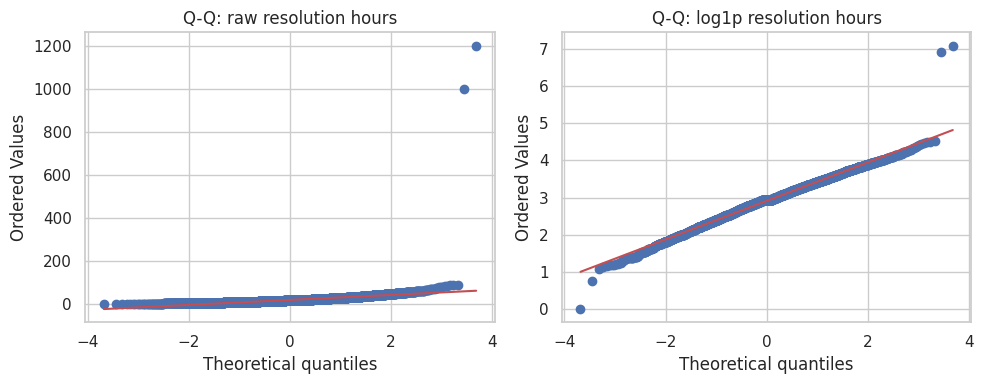

Shapiro p raw=3.269e-87; Shapiro p log1p=1.202e-16; raw skew=37.709; log skew=-0.103
At n≈6,000, normality tests have high power to detect tiny, practically irrelevant deviations; use Q-Q plots, skew, robustness, and the analysis goal—not p alone.


In [142]:

x=analysis.avg_resolution_hrs.dropna().astype(float)
p_raw=normality(x)
xlog=np.log1p(x[x>=0])
p_log=normality(xlog)
fig,ax=plt.subplots(1,2,figsize=(10,4))
stats.probplot(x,dist="norm",plot=ax[0]); ax[0].set_title("Q-Q: raw resolution hours")
stats.probplot(xlog,dist="norm",plot=ax[1]); ax[1].set_title("Q-Q: log1p resolution hours")
plt.tight_layout(); plt.show()
print(f"Shapiro p raw={pstr(p_raw)}; Shapiro p log1p={pstr(p_log)}; raw skew={x.skew():.3f}; log skew={xlog.skew():.3f}")
print("At n≈6,000, normality tests have high power to detect tiny, practically irrelevant deviations; use Q-Q plots, skew, robustness, and the analysis goal—not p alone.")


**Interpretation (Q30):** Resolution time is not normally distributed, but a log transform makes it much more symmetric and bell-shaped.

One-line interpretation: The heat map shows which numeric variables move together; correlation does not prove causation.

## Part D — Recommendation to the CEO

### Q31. One-page CEO memo

In [143]:
from pathlib import Path
import matplotlib
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib.units import cm
from reportlab.lib import colors
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont

# ---------- Values computed from the data ----------
DUPLICATES_REMOVED = 180          # set from your cleaning step if you have it as a variable
customers   = len(analysis)
overall     = analysis.churn.mean()
mean_bill   = analysis.monthly_charges.mean()
avoided     = customers * 0.05
replacement = avoided * 2400
billings    = avoided * mean_bill * 12
combined    = replacement + billings

def inr(x):
    """Indian digit grouping, e.g. 720000 -> 7,20,000"""
    s = f"{int(round(x))}"
    if len(s) <= 3:
        return s
    head, tail = s[:-3], s[-3:]
    parts = []
    while len(head) > 2:
        parts.insert(0, head[-2:]); head = head[:-2]
    if head:
        parts.insert(0, head)
    return ",".join(parts) + "," + tail

lakh = lambda x: f"{x/1e5:.2f}"

# ---------- Fonts (DejaVu ships with matplotlib and supports the ₹ symbol) ----------
font_dir = Path(matplotlib.get_data_path()) / "fonts" / "ttf"
pdfmetrics.registerFont(TTFont("DejaVu", str(font_dir / "DejaVuSans.ttf")))
pdfmetrics.registerFont(TTFont("DejaVu-Bold", str(font_dir / "DejaVuSans-Bold.ttf")))
pdfmetrics.registerFontFamily("DejaVu", normal="DejaVu", bold="DejaVu-Bold",
                              italic="DejaVu", boldItalic="DejaVu-Bold")

NAVY = colors.HexColor("#1F3A5F")
body  = ParagraphStyle("body", fontName="DejaVu", fontSize=9.5, leading=13.5, spaceAfter=6)
title = ParagraphStyle("title", parent=body, fontName="DejaVu-Bold", fontSize=15, leading=19,
                       textColor=NAVY, spaceAfter=8)
h2    = ParagraphStyle("h2", parent=body, fontName="DejaVu-Bold", fontSize=11.5, leading=15,
                       textColor=NAVY, spaceBefore=10, spaceAfter=6)
cell  = ParagraphStyle("cell", parent=body, fontSize=9, leading=12, spaceAfter=0)
cellh = ParagraphStyle("cellh", parent=cell, fontName="DejaVu-Bold", textColor=colors.white)
lever = ParagraphStyle("lever", parent=body, leftIndent=16, bulletIndent=0)

# ---------- Content ----------
story = []
story.append(Paragraph("CEO MEMO — KONNECT FIBERNET CHURN", title))
story.append(Paragraph(
    "<b>To:</b> Ms. Revati Deshmukh, CEO &nbsp; <b>Subject:</b> Findings and Monday priorities "
    "&nbsp; <b>Date:</b> 20 November 2026", body))

story.append(Paragraph("Executive finding", h2))
story.append(Paragraph(
    f"After removing {DUPLICATES_REMOVED} duplicate rows, the extract contains {customers:,} unique "
    f"customers. Overall churn is {overall:.1%}, above the 30% industry benchmark. The business should "
    "focus on contract retention and network reliability, not assume that lost customers are low-value.",
    body))

story.append(Paragraph("Board claims — verdicts", h2))
claims = [
    ("Sales: churn is 30%",
     f"Rejected. Observed churn is {overall:.1%}; one-proportion z-test p &lt; 0.001."),
    ("Marketing: average bill is ₹950",
     f"Rejected. Mean is about ₹{mean_bill:,.2f}; known-σ z-test p &lt; 0.001."),
    ("Churners are low-value",
     "Rejected. Churners average ₹894 vs stayers ₹825 per month."),
    ("OTT bundle retains customers",
     "Supported as association. Churn 28.2% with OTT vs 37.2% without; p &lt; 0.001."),
    ("Router upgrade gives ≥10% uplift",
     "Partly supported. Paired pilot speeds increased, but mean ratio uplift is about 7.0%, "
     "below 10%; no control group."),
    ("Resolution time is same in every city",
     "Rejected. City means range from 16.0 to 27.8 hours; ANOVA and Kruskal-Wallis p &lt; 0.001."),
    ("Women leave more",
     "No evidence. Gender × churn chi-square p = 0.952; fail to reject independence."),
    ("Cash/Cheque customers leave more",
     "Supported as association. Cash/Cheque churn is 42.6%, highest among payment methods."),
]
rows = [[Paragraph("Claim", cellh), Paragraph("Verdict and evidence", cellh)]]
rows += [[Paragraph(c, cell), Paragraph(v, cell)] for c, v in claims]
tbl = Table(rows, colWidths=[5.2*cm, 11.8*cm], repeatRows=1)
tbl.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), NAVY),
    ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#F2F5F9")]),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.HexColor("#B8C2CF")),
    ("VALIGN", (0, 0), (-1, -1), "TOP"),
    ("TOPPADDING", (0, 0), (-1, -1), 4), ("BOTTOMPADDING", (0, 0), (-1, -1), 4),
]))
story.append(tbl)

story.append(Paragraph("Top three levers — Monday morning", h2))
levers = [
    "<b>Move monthly customers to quarterly/annual plans.</b> Monthly churn is 47.1%, versus 25.2% "
    "quarterly and 14.1% annual. Pilot renewal offers and measure conversion/retention by cohort.",
    "<b>Prioritise old-router and outage hotspots.</b> Old-router churn is 43.2% versus 27.8% on new "
    "routers; outages are associated with lower CSAT. Target old ONT-v1 customers and the cities with "
    "longer resolution times; validate rollout with a control group.",
    "<b>Target OTT and payment-method interventions.</b> OTT customers show lower churn (28.2% vs 37.2%); "
    "Cash/Cheque customers show 42.6% churn. Test targeted OTT bundles and opt-in digital autopay "
    "rather than blanket discounts.",
]
for i, t in enumerate(levers, 1):
    story.append(Paragraph(t, lever, bulletText=f"{i}."))

story.append(Paragraph("Financial value of a 5-percentage-point churn reduction", h2))
story.append(Paragraph(
    f"At {customers:,} customers, a 5-point reduction retains approximately {avoided:,.0f} additional "
    f"customers. Replacement-cost avoidance = {avoided:,.0f} × ₹2,400 = ₹{inr(replacement)}. "
    f"At the observed mean bill of ₹{mean_bill:,.2f}, those customers represent approximately "
    f"₹{lakh(billings)} lakh in gross annual billings ({avoided:,.0f} × ₹{mean_bill:,.2f} × 12). "
    f"Combined gross value is approximately ₹{lakh(combined)} lakh. Billing is revenue, not profit; "
    f"this assumes all {avoided:,.0f} remain for a full year and excludes service costs/margins.", body))

story.append(Paragraph("Cautions and next data request", h2))
story.append(Paragraph(
    "The pilot has no control group, so it cannot prove the router caused the speed increase or reduced "
    "churn. The snapshot supports association, not causation. Next request: a randomised/matched router "
    "rollout and monthly customer-level history (churn date, renewals, outages, ticket timestamps, "
    "price changes and contribution margin).", body))

# ---------- Build PDF ----------
doc = SimpleDocTemplate("CEO_memo.pdf", pagesize=A4,
                        leftMargin=2*cm, rightMargin=2*cm, topMargin=2*cm, bottomMargin=2*cm,
                        title="CEO MEMO — KONNECT FIBERNET CHURN", author="Konnect Fibernet Analytics")
doc.build(story)
print("CEO memo saved as CEO_memo.pdf")

CEO memo saved as CEO_memo.pdf


**Interpretation (Q31):** The CEO memo pulls the test results together into clear findings and priorities, and is saved as CEO_memo.pdf.

### Q32. What this dataset cannot tell us; next data requests

In [144]:

limitations = pd.DataFrame([
    ["Causation of router upgrade", "Pilot has before/after observations but no randomized/control group; seasonal demand or other network changes may explain gains.", "Request matched non-pilot customers, upgrade dates, router model/firmware, neighbourhood node, and weekly speed/outage history; run a randomized phased rollout."],
    ["Why customers churn / true retention economics", "Snapshot records associations and a churn flag, but not the customer's stated reason, offer exposure, competitor availability, margin, or post-churn outcome.", "Collect cancellation reason, contact/offer history, competitor/price context, monthly contribution margin, payment failures, and exact disconnect date."]
],columns=["Limitation","Why it matters","Specific next data"])
display(limitations)


,Limitation,Why it matters,Specific next data
0,Causation of router upgrade,Pilot has before/after observations but no ran...,"Request matched non-pilot customers, upgrade d..."
1,Why customers churn / true retention economics,Snapshot records associations and a churn flag...,"Collect cancellation reason, contact/offer his..."


**Interpretation (Q32):** This table lists what the data can't tell us (why customers leave, whether the upgrade caused the gains) and what extra data to collect.

One-line interpretation: These combined segments help identify customer groups with relatively high or low churn for further investigation.

## Final validation checklist
- [ ] Notebook was run top-to-bottom and outputs are saved.
- [ ] `konnect_churn_clean.csv` was created by Q8.
- [ ] Review any categories mapped to missing/Other and confirm they are legitimate source variants.
- [ ] Export the Q31 memo text to a one-page `CEO_memo.pdf`.
- [ ] Upload notebook, cleaned CSV, and memo PDF to the submission folder.
